# Desarrollo 01: el algoritmo mas basico para medir el nivel del agua

**Que es este notebook.** La carpeta `desarrollo/` documenta como evoluciona el algoritmo que mide el nivel del agua
leyendo una **mira limnimetrica** (la regla pintada que se ve en la foto): se empieza por el ejemplo mas facil con el metodo
mas simple que funcione, y cada ejemplo siguiente prueba primero ese mismo metodo sin cambios y anade solo lo que ese
ejemplo obliga a anadir. Este es el primer paso. No hace falta conocer el resto del proyecto para leerlo.

**El ejemplo.** Camara fija sobre la mira de la compuerta del rio Meguro (Tokio), en un tramo con marea. Son 53 fotos de un
directo de YouTube, una cada 5 min, del 20-oct-2026 de 12:45 a 17:00 hora de Japon. Las capturo la prueba
`05_tokio_meguro_suimon`; aqui solo se leen.

**El metodo, en una frase.** El agua es un espejo: **la linea de agua es la fila de la mira donde lo de arriba y lo de abajo son
imagen especular**. Con esa fila, pasar a nivel es una resta, porque antes se endereza la mira para que cada fila valga
siempre el mismo nivel.

**Resultado.** Sin ajustar nada, frente al nivel oficial: **error absoluto medio 1.11 cm, sesgo -0.91 cm, 92 % de las medidas en +-2 cm y 98 % en +-5 cm** (50 fotos con lectura de 53; las otras 3 quedan bajo el minimo medible). Restando el sesgo, 0.84 cm. El peor fallo es un salto de -8 cm a las 13:25, que no se filtra a proposito. No es una prueba del todo a ciegas: ver la seccion 7.

| Seccion | |
|---|---|
| 0. Preparacion | librerias, rutas y utilidades; se tapa el nivel impreso en el video |
| 1. Una foto | que se ve y por que este ejemplo es el mas facil |
| 2. Lo que no funciono | cuatro ideas mas simples, probadas sobre las 53 fotos |
| 3. Configuracion | 4 puntos y 2 niveles para enderezar la mira; marcas de control; rango de medida |
| 4. El algoritmo | paso a paso sobre una foto: ventanas, espejo, curva de parecido, pico |
| 5. De fila a nivel | la conversion |
| 6. Toda la serie | una medida por foto, sin mirar todavia el nivel oficial |
| 7. Comparacion | una sola vez, con el nivel oficial y sin ajustar nada |
| 8. Video | camara a la izquierda, mira de cerca a la derecha |
| 9. Limitaciones | que se queda sin resolver y que tendra que mejorar el siguiente ejemplo |

## 0. Preparacion

Librerias, rutas y unas utilidades. Las fotos se leen de la carpeta de la prueba 05, que no se modifica; lo que produce este
notebook va a la carpeta `salidas/` de esta prueba, con el prefijo `01_`.

**El directo lleva impreso el nivel oficial** arriba a la derecha. `leer` tapa esa franja en negro al abrir cada foto: asi el
metodo no puede verlo y el nivel oficial solo se usa en la seccion 7.

In [1]:
import os
import sys
import glob
from datetime import datetime

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Rectangle, Polygon

sys.path.insert(0, os.path.join("..", "..", "herramientas"))
import escritor_video                     # escribe H.264 por una tuberia a ffmpeg (cv2.VideoWriter no sirve aqui)

plt.rcParams.update({"figure.dpi": 90, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#8a8984", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.labelcolor": "#52514e"})

# Colores de las figuras: rojo = linea de agua, azul = lo medido y las ventanas, naranja = nivel oficial
ROJO, AZUL, NARANJA, AMARILLO = "#e34948", "#2a78d6", "#eb6834", "#eda100"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"

DATOS = os.path.join("..", "..", "05_tokio_meguro_suimon", "datos")
CARPETA_FOTOS = os.path.join(DATOS, "capturas")
CSV_REFERENCIA = os.path.join(DATOS, "referencia_nivel.csv")     # solo se abre en la seccion 7
SALIDAS = "salidas"
os.makedirs(SALIDAS, exist_ok=True)

TEXTO_NIVEL = (430, 15, 960, 95)          # x0, y0, x1, y1: franja con el nivel oficial impreso


def leer(archivo):
    img = cv2.imread(os.path.join(CARPETA_FOTOS, archivo))
    x0, y0, x1, y1 = TEXTO_NIVEL
    img[y0:y1, x0:x1] = 0
    return img


def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def gris(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.float32)


def hora_de(archivo):
    # 20261020_124454.jpg -> 2026-10-20 12:44:54 (hora de Japon en que se pidio el frame)
    return datetime.strptime(os.path.basename(archivo)[:15], "%Y%m%d_%H%M%S")


fotos = sorted(os.path.basename(f) for f in glob.glob(os.path.join(CARPETA_FOTOS, "*.jpg")))
imgs = {a: leer(a) for a in fotos}
print("%d fotos, de %s a %s" % (len(fotos), hora_de(fotos[0]), hora_de(fotos[-1])))

53 fotos, de 2026-10-20 12:44:54 a 2026-10-20 17:00:00


## 1. Una foto

La mira es una placa vertical pintada en bloques de 0.5 m, con el numero de cada bloque **al pie del bloque**. Las alturas estan
en metros sobre **A.P.** (Arakawa Peil, el cero de referencia que usa Tokio). El agua solo se mueve en el bloque de abajo, el del
"1.5", verdoso por las algas; debajo de la linea de agua se ve el reflejo de la mira.

**Por que es el ejemplo mas facil**: camara fija, mira vertical, todo de dia, y el nivel oficial esta en el mismo cero que la
mira, asi que para comparar no hay que ajustar nada.

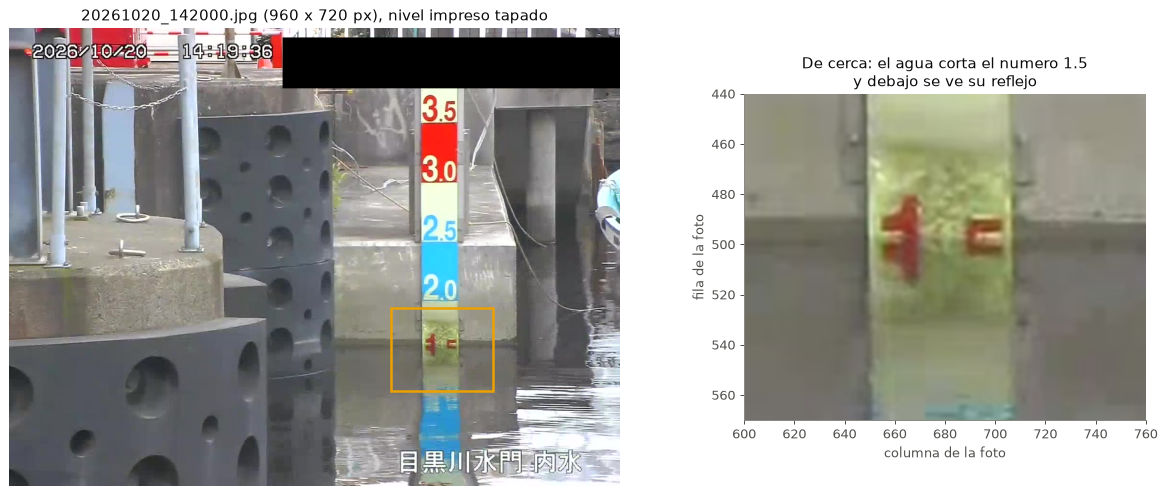

In [2]:
FOTO = "20261020_142000.jpg"            # la foto con la que se explica el metodo
img = imgs[FOTO]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [2.0, 1]})
ax[0].imshow(rgb(img)); ax[0].axis("off")
ax[0].set_title("%s (%d x %d px), nivel impreso tapado" % (FOTO, img.shape[1], img.shape[0]), color=TINTA)
ax[0].add_patch(Rectangle((600, 440), 160, 130, fill=False, ec=AMARILLO, lw=2))
ax[1].imshow(rgb(img[440:570, 600:760]), extent=[600, 760, 570, 440], interpolation="bicubic")
ax[1].set_title("De cerca: el agua corta el numero 1.5\ny debajo se ve su reflejo", color=TINTA)
ax[1].set_xlabel("columna de la foto"); ax[1].set_ylabel("fila de la foto")
plt.tight_layout()

## 2. Lo que no funciono

Antes de llegar al espejo se probaron cuatro ideas mas simples sobre las 53 fotos, sin mirar el nivel oficial. Se ensenan porque
explican por que el metodo es como es.

Las cuatro figuras son **quimogramas**: se toma la misma tira vertical de cada foto y se ponen una al lado de otra. El eje
horizontal es el tiempo y el vertical la fila de la foto, asi que lo fijo sale como bandas horizontales y lo que se mueve (el
agua, con la marea) como una curva. La linea roja es lo que detecta cada idea en cada foto.

1. **El mayor escalon claro a oscuro en la placa.** Lo primero que se le ocurre a uno: el agua es mas oscura que la placa. Pero el
   numero pintado y una mancha contrastan mas que el agua, y la deteccion se pega a filas fijas.
2. **El mayor escalon en el muro, junto a la placa.** Aqui no hay numeros y sale una curva muy suave, pero **es falsa**: sigue el
   borde de arriba del concreto mojado, no el agua. Una curva suave no es una curva correcta.
3. **Restar una foto de agua baja.** Lo fijo se cancela y deberia quedar solo el agua. Pero el reflejo verdoso se parece demasiado
   a la placa verdosa, y en la mayoria de las fotos no se llega a ninguna linea.
4. **La fila mas oscura del muro.** El concreto mojado y su reflejo forman una banda oscura alrededor del contacto, asi que sigue
   la marea; pero hay poco contraste y da saltos grandes entre fotos seguidas.

Idea 1, filas mas repetidas: {498: 19, 499: 11, 505: 7, 504: 4}
Idea 2, ultima foto (17:00): fila 505
Idea 3, fotos sin linea: 37 de 53


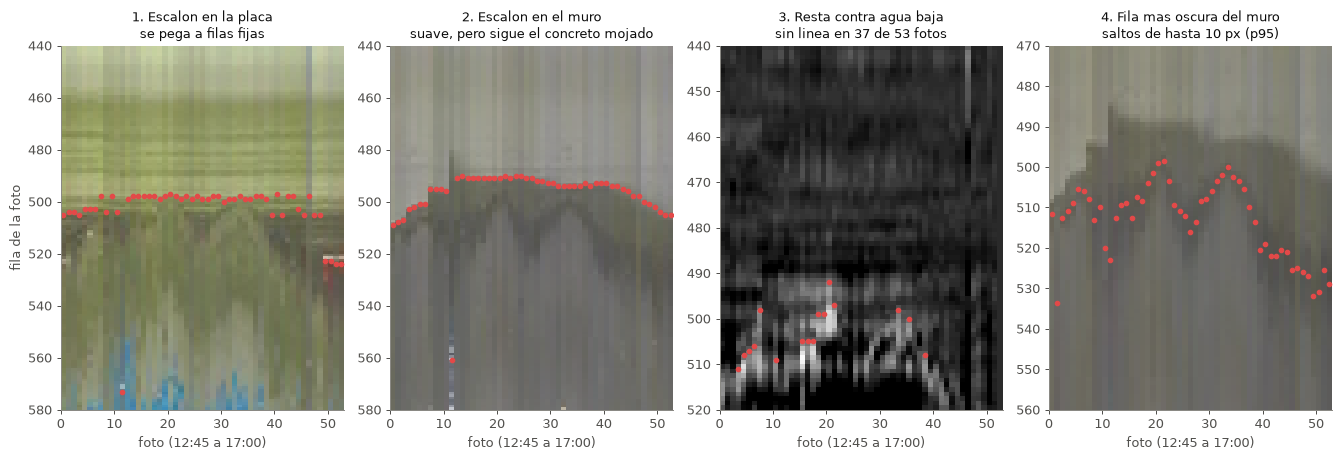

In [3]:
def escalon(p, w=4):
    # cuanto baja el brillo al pasar de las w filas de arriba a las w filas de abajo
    s = np.zeros(len(p))
    for r in range(w, len(p) - w):
        s[r] = p[r - w:r].mean() - p[r:r + w].mean()
    return s


def quimograma(x0, x1, y0, y1):
    # una columna por foto: el color medio de cada fila de la tira
    return np.stack([imgs[a][y0:y1, x0:x1].mean(1) for a in fotos], 1).astype(np.uint8)[..., ::-1]


def luminancia(a):
    return cv2.cvtColor(imgs[a], cv2.COLOR_BGR2LAB)[..., 0].astype(np.float32)


n = len(fotos)

# Idea 1 y 2: mayor escalon en la placa (columnas sin numero) y en el muro de la derecha
Y0, Y1 = 440, 580
PLACA, MURO = (674, 686), (715, 745)
fila_placa = np.array([Y0 + int(np.argmax(escalon(gris(imgs[a])[Y0:Y1, PLACA[0]:PLACA[1]].mean(1)))) for a in fotos])
fila_muro = np.array([Y0 + int(np.argmax(escalon(gris(imgs[a])[Y0:Y1, MURO[0]:MURO[1]].mean(1)))) for a in fotos])

# Idea 3: resta contra la foto de agua mas baja (17:00), en luminancia
L_ref = luminancia(fotos[-1])
R0, R1, SECO, BUSCA = 440, 520, (445, 480), (482, 516)
UMBRAL, SEGUIDAS = 8, 4


def perfil_resta(a):
    d = np.median(L_ref[R0:R1, 652:704] - luminancia(a)[R0:R1, 652:704], axis=1)   # positivo = mas oscuro que la referencia
    d = d - np.median(d[SECO[0] - R0:SECO[1] - R0])                                # lo que cambia toda la placa (la luz) fuera
    return np.convolve(d, np.ones(3) / 3, "same")


def primera_fila(d):
    for r in range(BUSCA[0] - R0, BUSCA[1] - R0 - SEGUIDAS + 1):
        if (d[r:r + SEGUIDAS] > UMBRAL).all():
            return R0 + r
    return np.nan


perfiles = np.array([perfil_resta(a) for a in fotos]).T
fila_resta = np.array([primera_fila(perfiles[:, i]) for i in range(n)])

# Idea 4: la fila mas oscura del muro, a cada lado de la placa
O0, O1 = 470, 560


def mas_oscura(L, x0, x1, w=5):
    p = np.convolve(L[O0:O1, x0:x1].mean(1), np.ones(w) / w, "valid")
    return O0 + w // 2 + int(np.argmin(p))


fila_oscura = np.array([(mas_oscura(luminancia(a), 620, 642) + mas_oscura(luminancia(a), 712, 734)) / 2 for a in fotos])

fig, ax = plt.subplots(1, 4, figsize=(15, 5.2))
paneles = [(quimograma(*PLACA, Y0, Y1), (Y0, Y1), fila_placa, "1. Escalon en la placa\nse pega a filas fijas"),
           (quimograma(*MURO, Y0, Y1), (Y0, Y1), fila_muro, "2. Escalon en el muro\nsuave, pero sigue el concreto mojado"),
           (None, (R0, R1), fila_resta, "3. Resta contra agua baja\nsin linea en %d de %d fotos" % (np.isnan(fila_resta).sum(), n)),
           (quimograma(620, 642, O0, O1), (O0, O1), fila_oscura, "4. Fila mas oscura del muro\nsaltos de hasta %.0f px (p95)"
            % np.percentile(np.abs(np.diff(fila_oscura)), 95))]
for a, (k, (y0, y1), filas, titulo) in zip(ax, paneles):
    if k is None:
        a.imshow(perfiles, cmap="gray", vmin=-5, vmax=25, aspect="auto", extent=[0, n, y1, y0], interpolation="nearest")
    else:
        a.imshow(k, aspect="auto", extent=[0, n, y1, y0], interpolation="nearest")
    a.plot(np.arange(n) + 0.5, filas, ".", color=ROJO, ms=7)
    a.set_title(titulo, fontsize=10.5, color=TINTA); a.set_xlabel("foto (12:45 a 17:00)")
ax[0].set_ylabel("fila de la foto")
plt.tight_layout()
print("Idea 1, filas mas repetidas:", pd.Series(fila_placa).value_counts().head(4).to_dict())
print("Idea 2, ultima foto (17:00): fila %d" % fila_muro[-1])
print("Idea 3, fotos sin linea: %d de %d" % (np.isnan(fila_resta).sum(), n))

La idea 2 merece una foto, porque es la que mas engana. A las 17:00 la marea ya bajo y el agua esta en el pie de la placa, que se
ve entero; el escalon del muro sigue muy por encima, en el borde del concreto que quedo mojado. **Por eso se mide sobre la placa
pintada, que no retiene esa humedad**, y no sobre el muro.

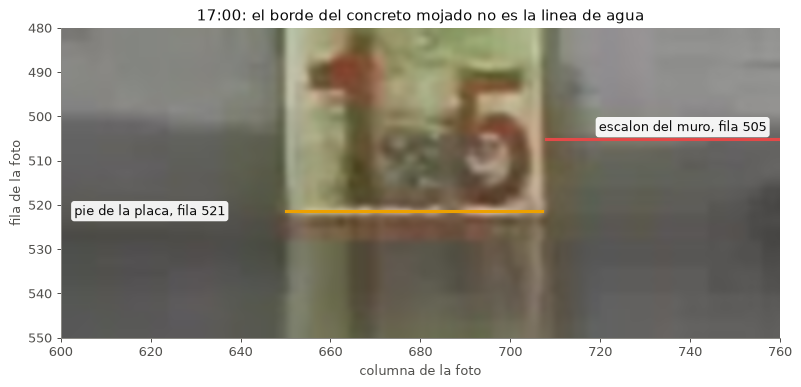

In [4]:
img17 = imgs["20261020_170000.jpg"]
fig, a = plt.subplots(figsize=(9, 4.4))
a.imshow(rgb(img17[480:550, 600:760]), extent=[600, 760, 550, 480], aspect="auto", interpolation="bicubic")
a.plot([708, 760], [fila_muro[-1]] * 2, color=ROJO, lw=2.5)
a.text(757, fila_muro[-1] - 1, "escalon del muro, fila %d" % fila_muro[-1], color=TINTA, ha="right", va="bottom",
       bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.92))
a.plot([650, 707], [521.4, 521.4], color=AMARILLO, lw=2.5)
a.text(603, 521.4, "pie de la placa, fila 521", color=TINTA, va="center",
       bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.92))
a.set_xlabel("columna de la foto"); a.set_ylabel("fila de la foto")
a.set_title("17:00: el borde del concreto mojado no es la linea de agua", color=TINTA)
plt.tight_layout()

## 3. Configuracion

La camara esta fija, asi que la mira ocupa siempre el mismo sitio y basta con decirle al metodo **una vez, a mano**, donde esta.
La idea de la configuracion es **enderezar la mira por separado**: pasar de la foto a una imagen donde la mira queda recta y cada
fila vale siempre el mismo nivel. Asi, medir se reduce a encontrar una fila.

### 3.1 Cuatro puntos y dos niveles

Solo hace falta marcar los dos bordes de la placa y dos niveles conocidos. Se usa la foto de las 17:00, con el agua mas baja, donde
se ve toda la placa. Son valores leidos a ojo sobre ampliaciones, de ahi la marca `>>> AJUSTABLE <<<`: son decisiones humanas y no
se cambian sin decirlo.

- **Bordes**: cada borde es la recta que pasa por dos puntos leidos, uno en la fila 160 y otro en la 510.
- **Niveles**: el borde de abajo del bloque "3.5" (fila 148.0) y el pie de la placa, que es 1.5 m (fila 521.4).

Las cuatro esquinas salen de cortar esos dos bordes con esas dos filas.

Esquinas: sup_izq (646.9, 148.0), sup_der (704.9, 148.0), inf_der (707.1, 521.4), inf_izq (650.1, 521.4)


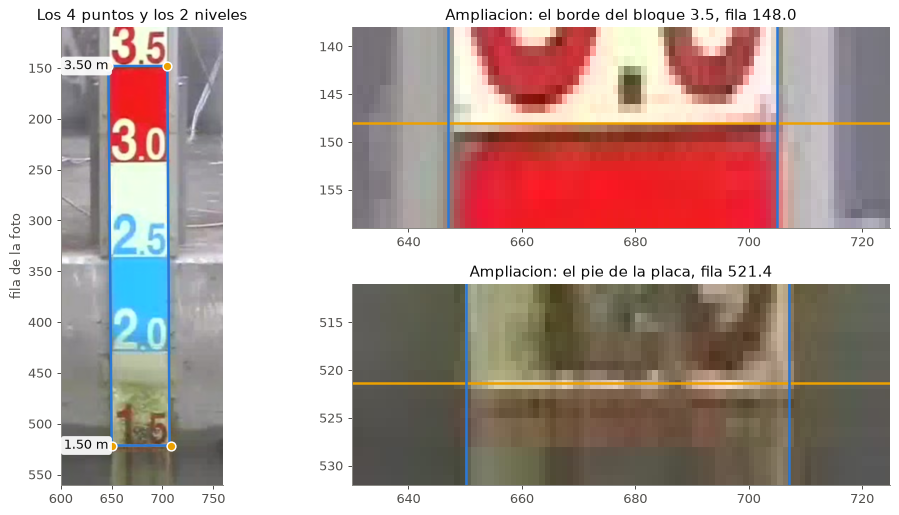

In [5]:
# >>> AJUSTABLE <<< (x, fila) de cada borde de la placa, leidos a ojo sobre ampliaciones de la foto de las 17:00
BORDE_IZQ = [(647, 160), (650, 510)]
BORDE_DER = [(705, 160), (707, 510)]

# >>> AJUSTABLE <<< dos niveles conocidos (cm sobre A.P.) y la fila donde estan, leidos a ojo
NIVEL_SUP, FILA_SUP = 350.0, 148.0        # borde de abajo del bloque 3.5
NIVEL_INF, FILA_INF = 150.0, 521.4        # pie de la placa


def recta_por(puntos):
    (xa, ya), (xb, yb) = puntos
    return lambda y: xa + (np.asarray(y, float) - ya) * (xb - xa) / (yb - ya)


x_izq, x_der = recta_por(BORDE_IZQ), recta_por(BORDE_DER)
SUP_IZQ, SUP_DER = (float(x_izq(FILA_SUP)), FILA_SUP), (float(x_der(FILA_SUP)), FILA_SUP)
INF_DER, INF_IZQ = (float(x_der(FILA_INF)), FILA_INF), (float(x_izq(FILA_INF)), FILA_INF)
print("Esquinas: sup_izq (%.1f, %.1f), sup_der (%.1f, %.1f), inf_der (%.1f, %.1f), inf_izq (%.1f, %.1f)"
      % (*SUP_IZQ, *SUP_DER, *INF_DER, *INF_IZQ))

ref = imgs["20261020_170000.jpg"]
fig = plt.figure(figsize=(13, 6.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.7], hspace=0.28, wspace=0.12)
a0 = fig.add_subplot(gs[:, 0])
a0.imshow(rgb(ref[110:560, 600:760]), extent=[600, 760, 560, 110], interpolation="bicubic")
a0.add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
for (x, y), texto in [(SUP_IZQ, "3.50 m"), (INF_IZQ, "1.50 m")]:
    a0.plot([x, x + (SUP_DER[0] - SUP_IZQ[0])], [y, y], "o", ms=7, mfc=AMARILLO, mec="white", mew=1.2)
    a0.text(603, y, texto, color=TINTA, va="center", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.92))
a0.set_title("Los 4 puntos y los 2 niveles", color=TINTA); a0.set_ylabel("fila de la foto")
for g_, fila, texto in [(gs[0, 1], FILA_SUP, "Ampliacion: el borde del bloque 3.5, fila %.1f"), (gs[1, 1], FILA_INF, "Ampliacion: el pie de la placa, fila %.1f")]:
    a = fig.add_subplot(g_)
    y0, y1 = int(fila) - 10, int(fila) + 11
    a.imshow(rgb(ref[y0:y1, 630:725]), extent=[630, 725, y1, y0], aspect="auto", interpolation="nearest")
    a.axhline(fila, color=AMARILLO, lw=2)
    a.axvline(float(x_izq(fila)), color=AZUL, lw=2); a.axvline(float(x_der(fila)), color=AZUL, lw=2)
    a.set_title(texto % fila, color=TINTA)

### 3.2 El tablero enderezado

Con esos puntos se calcula una transformacion que lleva la placa a un rectangulo: **`Tablero`**. El resultado es una imagen donde:

- la placa queda recta, con las filas horizontales;
- la fila 0 es el nivel superior (3.50 m) y cada 2 filas son 1 cm, asi que **cada fila vale siempre el mismo nivel**, en esta foto y
  en todas;
- se dejan 40 cm mas por debajo del pie de la placa, porque ahi esta el reflejo, que el metodo necesita.

`PX_POR_CM = 2.0` es casi la escala real de la camara (1.87 px/cm), para no inventar detalle. Se transforma en gris porque el
detector trabaja en gris.

**Por que enderezar no estropea el reflejo, sino que lo arregla.** La placa es vertical y el agua horizontal, asi que la imagen
reflejada de la placa queda **en el mismo plano que la placa**, como su prolongacion hacia abajo. Por eso la misma transformacion
endereza tambien el reflejo: en el tablero, reflejo y placa son simetricos fila a fila, sin tener que corregir nada mas. Aqui la
mira casi no esta inclinada (0.3 a 0.5 grados) y no se nota; con una mira inclinada es lo que hace que el espejo funcione.

Tablero de 62 columnas x 480 filas


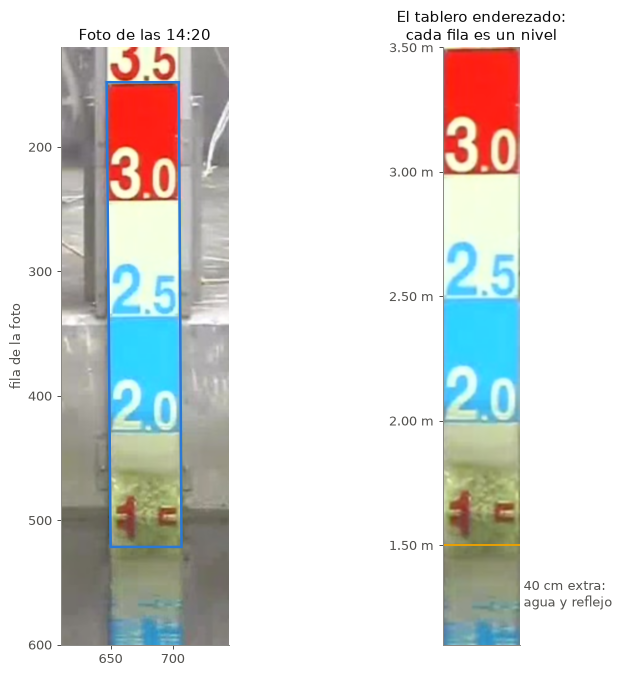

In [6]:
class Tablero:
    # 4 puntos + 2 niveles -> tablero enderezado con lados paralelos: cada fila es un nivel fijo
    def __init__(self, sup_izq, sup_der, inf_der, inf_izq, nivel_sup, nivel_inf, px_por_cm, ancho_px, extra_cm):
        self.nivel_sup, self.px_por_cm = float(nivel_sup), float(px_por_cm)
        alto = (nivel_sup - nivel_inf) * px_por_cm
        src = np.float64([sup_izq, sup_der, inf_der, inf_izq])
        dst = np.float64([[0, 0], [ancho_px, 0], [ancho_px, alto], [0, alto]])
        A = np.hstack([src, np.ones((4, 1))])
        self.M = np.array([np.linalg.lstsq(A, dst[:, i], rcond=None)[0] for i in (0, 1)])   # afin por minimos cuadrados
        self.M_inv = cv2.invertAffineTransform(self.M)
        self.tam = (int(ancho_px), int(alto + extra_cm * px_por_cm))

    def enderezar(self, img):
        return cv2.warpAffine(img, self.M, self.tam, flags=cv2.INTER_LINEAR)

    def fila_de(self, nivel):
        return (self.nivel_sup - nivel) * self.px_por_cm

    def nivel_de(self, fila):
        return self.nivel_sup - fila / self.px_por_cm

    def a_tablero(self, x, y):
        return self.M @ np.array([x, y, 1.0])       # punto de la foto -> (columna, fila) del tablero

    def a_foto(self, col, fila):
        return self.M_inv @ np.array([col, fila, 1.0])   # punto del tablero -> (x, y) de la foto


PX_POR_CM = 2.0        # >>> AJUSTABLE <<< filas del tablero por cm (casi la escala de la camara, 1.87 px/cm)
ANCHO = 62             # >>> AJUSTABLE <<< columnas del tablero (la placa mide 58 px de ancho)
EXTRA_CM = 40.0        # >>> AJUSTABLE <<< cm por debajo del nivel inferior, para que entre el reflejo

T = Tablero(SUP_IZQ, SUP_DER, INF_DER, INF_IZQ, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
tablero = T.enderezar(img)
alto_total = T.tam[1]

fig, ax = plt.subplots(1, 2, figsize=(9, 7.6))
ax[0].imshow(rgb(img[120:600, 610:745]), extent=[610, 745, 600, 120], interpolation="bicubic")
ax[0].add_patch(Polygon([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ], closed=True, fill=False, ec=AZUL, lw=2))
ax[0].set_title("Foto de las 14:20", color=TINTA); ax[0].set_ylabel("fila de la foto")
ax[1].imshow(rgb(tablero), extent=[0, ANCHO, alto_total, 0], interpolation="bicubic")
niveles = np.arange(350, 149, -50)
ax[1].set_yticks([T.fila_de(c) for c in niveles]); ax[1].set_yticklabels(["%.2f m" % (c / 100) for c in niveles])
ax[1].set_xticks([]); ax[1].set_title("El tablero enderezado:\ncada fila es un nivel", color=TINTA)
ax[1].axhline(T.fila_de(NIVEL_INF), color=AMARILLO, lw=1.5)
ax[1].text(ANCHO + 3, (T.fila_de(NIVEL_INF) + alto_total) / 2, "40 cm extra:\nagua y reflejo", va="center", color=TINTA2)
plt.tight_layout()
print("Tablero de %d columnas x %d filas" % T.tam)

### 3.3 Marcas de control

Hay otros tres bordes de bloque (2.0, 2.5 y 3.0 m) que **no se usan para enderezar**. Sirven para comprobar el resultado: se ve en
que nivel caen dentro del tablero y se compara con el que deberian tener. Un error de 0.4 cm es lo que da leer una fila a ojo con
1.87 px/cm, asi que el tablero es tan bueno como la lectura.

### 3.4 Por que lados paralelos y no una correccion de perspectiva completa

Lo primero que se piensa con 4 puntos es una **homografia**, la correccion de perspectiva completa. Se probo, y aqui **empeora**. La
placa es larga y angosta (373 px de alto y 58 de ancho): si una esquina se lee medio pixel mal, la homografia cree que la placa se
estrecha por perspectiva y deforma todas las filas. Con **lados paralelos** (una transformacion afin) esa diferencia de ancho no
puede convertirse en perspectiva.

La escala de esta camara no necesita ese termino: los cuatro tramos de 50 cm miden 1.88, 1.84, 1.87 y 1.88 px/cm, constantes dentro
del error de lectura. Si un ejemplo posterior tiene perspectiva de verdad, las marcas de control lo diran y sera ese ejemplo el que
obligue a anadirla.

In [7]:
# Fila de la foto de cada marca que no entra en el ajuste, leida a ojo
MARCAS_CONTROL = {300: 242.0, 250: 335.5, 200: 427.4}

fuente = np.float32([SUP_IZQ, SUP_DER, INF_DER, INF_IZQ])
alto_placa = (NIVEL_SUP - NIVEL_INF) * PX_POR_CM
destino = np.float32([[0, 0], [ANCHO, 0], [ANCHO, alto_placa], [0, alto_placa]])
H_libre = cv2.getPerspectiveTransform(fuente, destino)


def fila_homografia(H, x, y):
    return float(cv2.perspectiveTransform(np.float32([[[x, y]]]), H)[0, 0][1])


filas_tabla = []
for c, f in sorted(MARCAS_CONTROL.items()):
    x = float(x_izq(f) + x_der(f)) / 2
    filas_tabla.append({"marca (m)": c / 100,
                        "lados paralelos: medido - real (cm)": T.nivel_de(T.a_tablero(x, f)[1]) - c,
                        "homografia de 4 esquinas: medido - real (cm)": T.nivel_de(fila_homografia(H_libre, x, f)) - c})
tabla_marcas = pd.DataFrame(filas_tabla).set_index("marca (m)").round(2)

# Sensibilidad: se mueve 0.5 px una esquina y se mira cuanto cambia la lectura a media placa (marca de 2.5 m)
movida = fuente.copy(); movida[0, 0] += 0.5
f_mid = MARCAS_CONTROL[250]; x_mid = float(x_izq(f_mid) + x_der(f_mid)) / 2
cambio_h = abs(fila_homografia(cv2.getPerspectiveTransform(movida, destino), x_mid, f_mid) - fila_homografia(H_libre, x_mid, f_mid)) / PX_POR_CM
T_movida = Tablero(tuple(movida[0]), SUP_DER, INF_DER, INF_IZQ, NIVEL_SUP, NIVEL_INF, PX_POR_CM, ANCHO, EXTRA_CM)
cambio_p = abs(T_movida.a_tablero(x_mid, f_mid)[1] - T.a_tablero(x_mid, f_mid)[1]) / PX_POR_CM
print("Mover 0.5 px la esquina superior izquierda cambia la lectura a media placa:")
print("  homografia de 4 esquinas: %.2f cm" % cambio_h)
print("  lados paralelos:          %.2f cm" % cambio_p)
tabla_marcas

Mover 0.5 px la esquina superior izquierda cambia la lectura a media placa:
  homografia de 4 esquinas: 0.43 cm
  lados paralelos:          0.00 cm


,lados paralelos: medido - real (cm),homografia de 4 esquinas: medido - real (cm)
marca (m),,
2.0,0.35,1.05
2.5,-0.43,0.50
3.0,-0.35,0.35


### 3.5 El rango de medida

Falta decir **entre que niveles se mide**, y aqui hay que distinguir dos cosas:

- **Minimo medible: 1.50 m**, el pie de la placa. Si el agua esta por debajo, ya no toca la mira: el resultado se informa como
  "<= 1.50 m", no como una lectura. Se busca un poco mas abajo (hasta 1.44 m) precisamente para poder detectar ese caso.
- **Maximo donde buscar: 1.70 m**, no el tope de la regla (3.50 m). Es hasta donde llega el agua en esta serie, y se eligio mirando
  las fotos: por encima, la mira esta siempre seca.

Este maximo es una decision que importa: los bloques lisos y los numeros de la mira seca tambien pueden parecer un espejo. En la
seccion 4.5 se muestra lo que pasa si se busca en toda la regla.

In [8]:
NIVEL_MINIMO = 150.0          # >>> AJUSTABLE <<< cm: pie de la placa, por debajo no hay lectura
NIVEL_MAX_AGUA = 170.0        # >>> AJUSTABLE <<< cm: por encima la mira esta siempre seca en esta serie (visto en las fotos)
NIVEL_MIN_BUSQUEDA = 144.0    # >>> AJUSTABLE <<< cm: se busca algo por debajo del minimo para detectar ese caso